### Create graph from edges

In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""


import pandas as pd

df = pd.read_csv("../../../../0_DATA/HAHN/03a_all_edges_all_ffs.csv")
# Remove rows with NaNs in specific columns
df = df.dropna(subset=["DDG_OpenFF-1.0","DDG_OpenFF-2.0","DDG_OPLS3e", "DDG_GAFF2", "DDG_cGenFF", "DDG_Consensus_OpenFF_GAFF2_cGenFF"])
df

,Unnamed: 0,target,edge,ligandA,ligandB,unit,DDG_Exp.,dDDG_Exp.,DDG_OpenFF-1.0,dDDG_OpenFF-1.0,...,error_GAFF2,abserror_GAFF2,error_cGenFF,abserror_cGenFF,error_Consensus_OpenFF_GAFF2_cGenFF,abserror_Consensus_OpenFF_GAFF2_cGenFF,error_Consensus_OpenFF_GAFF2,abserror_Consensus_OpenFF_GAFF2,error_Consensus_all,abserror_Consensus_all
0,jnk1_edge_17124-1_18631-1,jnk1,edge_17124-1_18631-1,17124-1,18631-1,kilocalories / mole,0.26,0.37000,1.190000,0.096086,...,1.071262,1.071262,0.516769,0.516769,0.646112,0.646112,0.784876,0.784876,1.222263,1.222263
1,jnk1_edge_17124-1_18634-1,jnk1,edge_17124-1_18634-1,17124-1,18634-1,kilocalories / mole,-0.33,0.29000,0.580000,0.128639,...,0.829522,0.829522,0.580956,0.580956,0.852556,0.852556,0.928604,0.928604,0.798413,0.798413
2,jnk1_edge_18626-1_18624-1,jnk1,edge_18626-1_18624-1,18626-1,18624-1,kilocalories / mole,0.38,0.21000,0.556667,0.099301,...,0.745717,0.745717,-0.265277,0.265277,0.309516,0.309516,0.616033,0.616033,0.446727,0.446727
3,jnk1_edge_18626-1_18625-1,jnk1,edge_18626-1_18625-1,18626-1,18625-1,kilocalories / mole,0.77,0.21000,-0.030000,0.107462,...,-0.062543,0.062543,-0.294379,0.294379,-0.388337,0.388337,-0.155679,0.155679,0.143932,0.143932
4,jnk1_edge_18626-1_18627-1,jnk1,edge_18626-1_18627-1,18626-1,18627-1,kilocalories / mole,0.39,0.22000,0.140000,0.046151,...,0.042600,0.042600,-0.232256,0.232256,-0.020344,0.020344,0.064101,0.064101,-0.124060,0.124060
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1123,tnks2_edge_8e_8a,tnks2,edge_8e_8a,8e,8a,kilocalories / mole,-0.56,0.39598,-1.786667,0.244897,...,0.540000,0.540000,1.466667,1.466667,0.933333,0.933333,0.750000,0.750000,0.593333,0.593333
1124,tnks2_edge_8e_8b,tnks2,edge_8e_8b,8e,8b,kilocalories / mole,-1.69,0.39598,-2.750000,0.479734,...,0.486667,0.486667,1.016667,1.016667,0.200000,0.200000,0.445000,0.445000,0.405000,0.405000
1125,tnks2_edge_8e_8c,tnks2,edge_8e_8c,8e,8c,kilocalories / mole,0.12,0.39598,0.153333,0.178701,...,-0.530000,0.530000,0.010000,0.010000,-0.423333,0.423333,-0.665000,0.665000,-0.128333,0.128333
1126,tnks2_edge_8f_5m,tnks2,edge_8f_5m,8f,5m,kilocalories / mole,-0.89,0.39598,-2.433333,0.246799,...,0.503333,0.503333,-1.020000,1.020000,-0.506667,0.506667,0.050000,0.050000,-0.664167,0.664167


In [2]:
import networkx as nx

graphs = {}

# Group by 'target' and build one DiGraph per group
for target, group in df.groupby('target'):
    G = nx.DiGraph()
    for _, row in group.iterrows():
        node1 = row['ligandA']
        node2 = row['ligandB']
        weight = row['DDG_OPLS3e']
        G.add_edge(node1, node2, weight=weight)
    graphs[target] = G  # store graph per target


### Calculate ddG values from graph

In [3]:
# Make sure all graphs are fully connected
for target, G in graphs.items():
    if nx.is_connected(G.to_undirected()):
        continue
    else:
        raise NameError("not fuly conected graph")

In [4]:
total_expected_paths = 0

for target, G in graphs.items():
    n = len(G.nodes)
    expected = n * (n - 1)
    total_expected_paths += expected
    #print(f"{target}: {expected} directed paths")
    #print(n_nodes)

print(f"\nTotal expected paths across all targets: {total_expected_paths}")


Total expected paths across all targets: 17988


In [5]:
from itertools import permutations

def signed_path_weight(G, path, weight='weight'):
    total = 0
    for u, v in zip(path, path[1:]):
        if G.has_edge(u, v):
            total += G[u][v][weight]
        else:
            total -= G[v][u][weight]
    return total

results = []
same_length_path_counts = []

for target, G in graphs.items():
    UG = G.to_undirected()
    ligands = list(UG.nodes)

    for source, target_node in permutations(ligands, 2):
        if nx.has_path(UG, source, target_node):
            all_paths = list(nx.all_shortest_paths(UG, source, target_node))
            n_paths = len(all_paths)
            same_length_path_counts.append(n_paths) 

            for path in all_paths:
                ddG = signed_path_weight(G, path)
                results.append({
                    'target': target,
                    'ligandA': source,
                    'ligandB': target_node,
                    'path': path,
                    'n_steps': len(path) - 1,
                    'sum_ddG': ddG,
                    'n_paths': n_paths
                })
        else:
            raise NameError(f"no path between {source} and {target_node} in {target}")


df_G = pd.DataFrame(results)

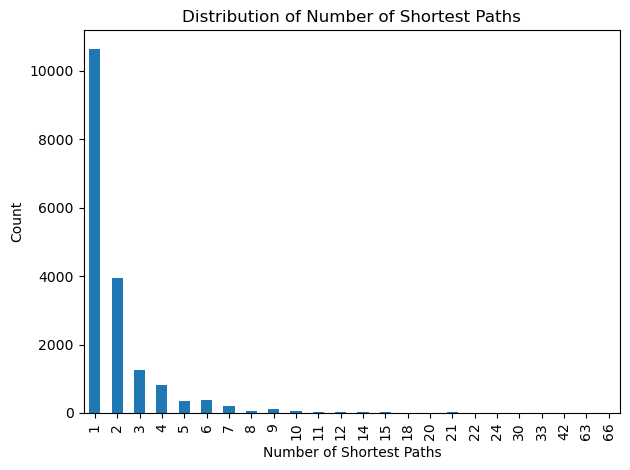

In [6]:
import matplotlib.pyplot as plt

plt.figure()
pd.Series(same_length_path_counts).value_counts().sort_index().plot(kind='bar')
plt.xlabel('Number of Shortest Paths')
plt.ylabel('Count')
plt.title('Distribution of Number of Shortest Paths')
plt.tight_layout()
plt.show()

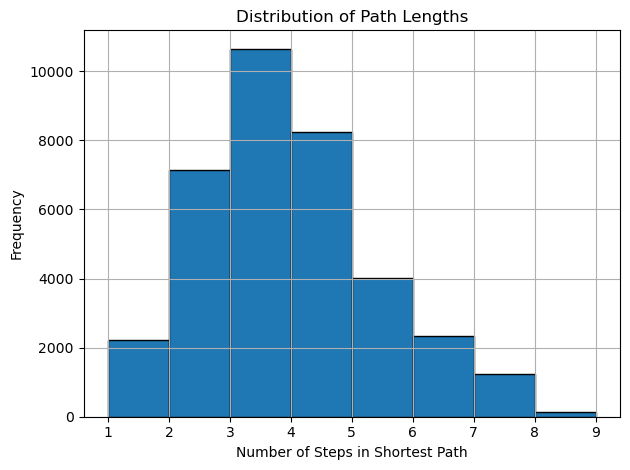

In [7]:
### Show n steps
import matplotlib.pyplot as plt

plt.figure()
df_G['n_steps'].hist(bins=range(1, df_G['n_steps'].max() + 2), edgecolor='black')
plt.xlabel('Number of Steps in Shortest Path')
plt.ylabel('Frequency')
plt.title('Distribution of Path Lengths')
plt.tight_layout()
plt.show()


### Compare to ddG values obtained ML (Maximum Likelihood/Arsenic)

In [8]:
# Add 'pair' column to df_G (df_paths) with formatted ligand pair key
df_G['pair'] = df_G.apply(
    lambda row: f"lig_{row['ligandA']}__lig_{row['ligandB']}", axis=1
)
df_G

,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair
0,bace,CAT-13a,CAT-13m,"[CAT-13a, CAT-13m]",1,-2.153442,1,lig_CAT-13a__lig_CAT-13m
1,bace,CAT-13a,CAT-17g,"[CAT-13a, CAT-17g]",1,0.869981,1,lig_CAT-13a__lig_CAT-17g
2,bace,CAT-13a,CAT-17i,"[CAT-13a, CAT-17i]",1,0.162524,1,lig_CAT-13a__lig_CAT-17i
3,bace,CAT-13a,CAT-13b,"[CAT-13a, CAT-17g, CAT-13b]",2,-0.184034,1,lig_CAT-13a__lig_CAT-13b
4,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17g, CAT-13c]",2,0.750478,2,lig_CAT-13a__lig_CAT-13c
...,...,...,...,...,...,...,...,...
35973,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_28, ejm_31, ejm_49, ejm_50]",4,1.228489,2,lig_jmc_30__lig_ejm_50
35974,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_23, ejm_55, ejm_42, ejm_50]",4,1.221319,2,lig_jmc_30__lig_ejm_50
35975,tyk2,jmc_30,jmc_23,"[jmc_30, jmc_23]",1,-0.329828,1,lig_jmc_30__lig_jmc_23
35976,tyk2,jmc_30,jmc_27,"[jmc_30, jmc_28, jmc_27]",2,-0.174474,2,lig_jmc_30__lig_jmc_27


In [9]:
# Sanity check
df_G[df_G["n_paths"]> 1]

,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair
4,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17g, CAT-13c]",2,0.750478,2,lig_CAT-13a__lig_CAT-13c
5,bace,CAT-13a,CAT-13c,"[CAT-13a, CAT-17i, CAT-13c]",2,0.473231,2,lig_CAT-13a__lig_CAT-13c
6,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-13i, CAT-13d]",3,-0.889101,6,lig_CAT-13a__lig_CAT-13d
7,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-17d, CAT-13d]",3,-1.087476,6,lig_CAT-13a__lig_CAT-13d
8,bace,CAT-13a,CAT-13d,"[CAT-13a, CAT-17g, CAT-13b, CAT-13d]",3,-1.283461,6,lig_CAT-13a__lig_CAT-13d
...,...,...,...,...,...,...,...,...
35971,tyk2,jmc_30,ejm_47,"[jmc_30, jmc_23, ejm_55, ejm_47]",3,1.376673,2,lig_jmc_30__lig_ejm_47
35973,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_28, ejm_31, ejm_49, ejm_50]",4,1.228489,2,lig_jmc_30__lig_ejm_50
35974,tyk2,jmc_30,ejm_50,"[jmc_30, jmc_23, ejm_55, ejm_42, ejm_50]",4,1.221319,2,lig_jmc_30__lig_ejm_50
35976,tyk2,jmc_30,jmc_27,"[jmc_30, jmc_28, jmc_27]",2,-0.174474,2,lig_jmc_30__lig_jmc_27


In [10]:
# group by pair & target, compute avg and range of sum_ddG
df_G['avg_sum_ddG'] = df_G.groupby(['pair', 'target'])['sum_ddG'].transform('mean')
df_G['ddG_range']  = df_G.groupby(['pair', 'target'])['sum_ddG'].transform(lambda x: x.max() - x.min())

# filter rows where n_paths > 1
df_G_filtered = df_G[df_G['n_paths'] > 1]

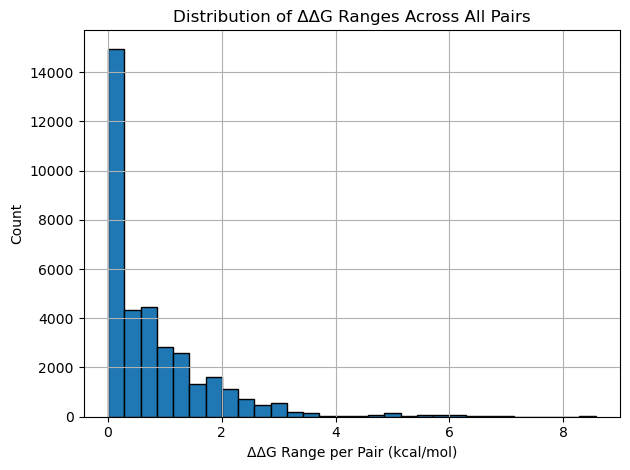

In [11]:
# Plot the ddG ranges
import matplotlib.pyplot as plt

plt.figure()
df_G['ddG_range'].hist(bins=30, edgecolor='black')
plt.xlabel('ΔΔG Range per Pair (kcal/mol)')
plt.ylabel('Count')
plt.title('Distribution of ΔΔG Ranges Across All Pairs')
plt.tight_layout()
plt.show()


In [12]:
# Look at outliers wrt ddG_range
outliers = df_G[df_G["ddG_range"]> 5]
print(len(df_G))
print(len(outliers))
print(len(outliers)/len(df_G)) 
outliers.head(30)

35978
490
0.01361943409861582


,target,ligandA,ligandB,path,n_steps,sum_ddG,n_paths,pair,avg_sum_ddG,ddG_range
5355,cdk2,26,31,"[26, 28, 31]",2,-1.496176,2,lig_26__lig_31,-4.151530,5.310707
5356,cdk2,26,31,"[26, 30, 31]",2,-6.806883,2,lig_26__lig_31,-4.151530,5.310707
5357,cdk2,26,32,"[26, 1h1s, 1oiy, 32]",3,-0.786329,6,lig_26__lig_32,-1.919216,6.202199
5358,cdk2,26,32,"[26, 1h1q, 1oiy, 32]",3,-0.948853,6,lig_26__lig_32,-1.919216,6.202199
5359,cdk2,26,32,"[26, 1oi9, 1oiy, 32]",3,-0.614245,6,lig_26__lig_32,-1.919216,6.202199
5360,cdk2,26,32,"[26, 29, 1oiy, 32]",3,-0.843690,6,lig_26__lig_32,-1.919216,6.202199
5361,cdk2,26,32,"[26, 28, 31, 32]",3,-1.505736,6,lig_26__lig_32,-1.919216,6.202199
5362,cdk2,26,32,"[26, 30, 31, 32]",3,-6.816444,6,lig_26__lig_32,-1.919216,6.202199
5405,cdk2,1oiu,31,"[1oiu, 1h1q, 1oiy, 31]",3,0.198375,3,lig_1oiu__lig_31,-1.452358,5.310707
5406,cdk2,1oiu,31,"[1oiu, 26, 28, 31]",3,0.377629,3,lig_1oiu__lig_31,-1.452358,5.310707


### Hahn: Is the error maybe due to bad edges (ddG calculations)? -> Compare ddG_GRAPGH (FEP) to  ddG experimental

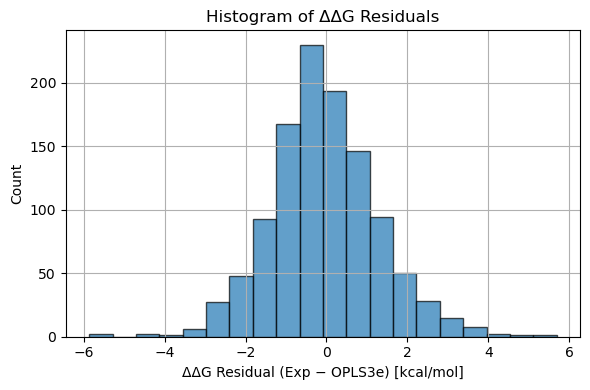

In [13]:
import matplotlib.pyplot as plt

# === Parameters ===
alpha = 0.7
bins = 20

# === Compute residuals ===
df['Residual'] = df['DDG_Exp.'] - df['DDG_OPLS3e']

# === Plot histogram ===
plt.figure(figsize=(6, 4))
plt.hist(df['Residual'], bins=bins, alpha=alpha, edgecolor='black')

plt.xlabel('ΔΔG Residual (Exp − OPLS3e) [kcal/mol]')
plt.ylabel('Count')
plt.title('Histogram of ΔΔG Residuals')
plt.grid(True)
plt.tight_layout()
plt.show()


### Save ddG Values

In [14]:
data_for_df = []

for _, row in df_G.iterrows():
    ligandA = row['ligandA']  # extract ligandA from current row
    ligandB = row['ligandB']  # extract ligandB from current row
    target = row['target']    # extract target from current row
    avg_sum_ddG = row['avg_sum_ddG']  # extract avg_sum_ddG from current row

    name = f"lig_{ligandA}__lig_{ligandB}"  # prepend "lig" to names
    data_for_df.append({'target': target, 'pair': name, 'DDG': avg_sum_ddG})
    
res_df_G = pd.DataFrame(data_for_df)
res_df_G.to_csv('OPLS_FEP_DDG_FROM_GRAPH.csv', index=False)